In [2]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import rcParams
from matplotlib.ticker import ScalarFormatter
%matplotlib inline
import pandas as pd
from planet_cookbook import read_reports as rr
import os
import rebound
import seaborn as sns

sol_to_earth = 332946.078
G = 6.6743* 10**(-11) #N⋅m2/kg2
M_sun = 1.989e+33 #g
AU = 1.496e+13 #cm

In [ ]:
params = {
   'axes.labelsize': 15,
   'font.size': 15,
   'legend.fontsize': 12,
   'xtick.labelsize': 15,
   'ytick.labelsize': 15,
   'text.usetex': True, #to use TeX in your labels
   'font.family':'serif',
   'axes.titlesize': 15
   }
rcParams.update(params)

#Color-blind friendly pallete
colors = [
    "#0C7BDC",  # Vibrant Blue
    "#E66100",  # Bright Orange
    "#40B0A6",  # Teal/Aqua
    "#8B8D8B",  # Medium Grey
    "#5D3A9B"   # Muted Purple
]

vib_blue = "#0C7BDC"
teal = "#40B0A6"
purple = "#5D3A9B" 

dot_scale = 500

In [85]:
solar_system_df = pd.read_csv('../solarsystem.csv')
mercury = solar_system_df[solar_system_df['name'] == 'Mercury']
venus = solar_system_df[solar_system_df['name'] == 'Venus']
earth = solar_system_df[solar_system_df['name'] == 'Earth']
mars = solar_system_df[solar_system_df['name'] == 'Mars']

def plot_solsys(dot_scale):
    plt.scatter(0.387, 0.7, color='#D81B60', edgecolors='black', linewidths=1, label = 'Mercury', zorder=2)
    plt.annotate('☿', [0.387, 0.7], fontsize=16, usetex=False)

    plt.scatter(0.723, 0.3, color='#FFC107', edgecolors='black', linewidths=1, label = 'Venus', zorder=2)
    plt.annotate('♀', [0.723, 0.3], fontsize=16, usetex=False)

    plt.scatter(1, 0.33, color='#1E88E5', edgecolors='black', linewidths=1, label = 'Earth', zorder=2)
    plt.annotate('⊕', [1, 0.33], fontsize=16, usetex=False)

    plt.scatter(1.52, 0.24, color='#004D40', edgecolors='black', linewidths=1, label = 'Mars', zorder=2)
    plt.annotate('♂', [1.52, 0.24], fontsize=16, usetex=False)

# Step functions

In [ ]:
cham_bi_tajer_full_df = pd.read_csv("../cham_bi_tajer/cham_bi_tajer_grid_fulldf.csv")
ueda_v5_full_df = pd.read_csv("../ueda_v5/ueda_v5_grid_fulldf.csv")
cham_cont_full_df = pd.read_csv("../cham_cont/cham_cont_grid_fulldf.csv")

In [22]:
def bin_over_a(df, bin_edges):
    means = []
    stds = []
    centers = []
    for i in range(len(bin_edges) - 1):
        c_min = bin_edges[i]
        c_max = bin_edges[i+1]

        in_bin = df[(df['semi'] >= c_min) & (df['semi'] < c_max)]

        if len(in_bin) > 0:
            mean_cmf = in_bin['cmf'].mean()
            std_cmf = in_bin['cmf'].std()

            bin_center = (c_min + c_max)/2

            centers.append(bin_center)
            means.append(mean_cmf)
            stds.append(std_cmf)
    centers_array = np.array(centers)
    means_array = np.array(means)
    stds_array = np.array(stds)

    return centers_array, means_array, stds_array

In [40]:
a_bin_edges = np.linspace(0.2, 2.2, 10)

ueda_bin_centers, ueda_cmf_means, ueda_cmf_stds = bin_over_a(ueda_v5_full_df, a_bin_edges)
cham_b_bin_centers, cham_b_cmf_means, cham_b_cmf_stds = bin_over_a(cham_bi_tajer_full_df, a_bin_edges)
cham_c_bin_centers, cham_c_cmf_means, cham_c_cmf_stds = bin_over_a(cham_cont_full_df, a_bin_edges)

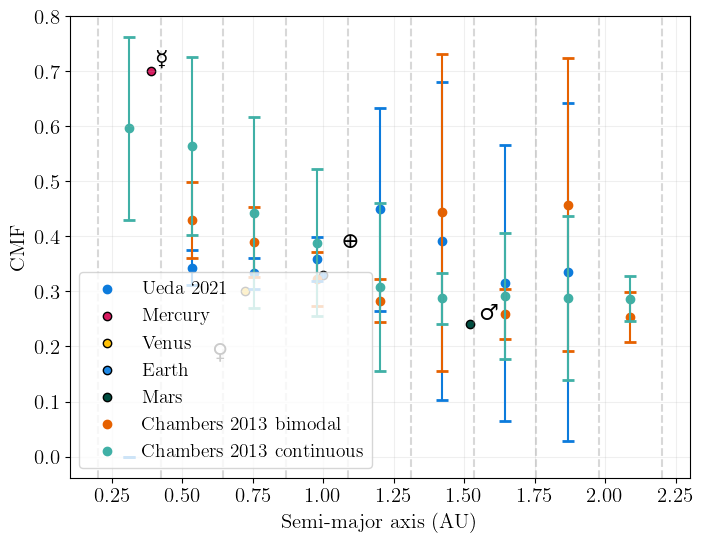

In [75]:
plt.figure(figsize=(8,6))
plt.errorbar(ueda_bin_centers, ueda_cmf_means, yerr=ueda_cmf_stds, fmt = 'None', color = colors[0], capsize=4, capthick=2)
plt.scatter(ueda_bin_centers[1:], ueda_cmf_means[1:], color = colors[0], label = 'Ueda 2021')
plot_solsys(2)

plt.errorbar(cham_b_bin_centers, cham_b_cmf_means, yerr=cham_b_cmf_stds, fmt = 'None', color = colors[1], capsize=4, capthick=2)
plt.scatter(cham_b_bin_centers, cham_b_cmf_means, color = colors[1], label = 'Chambers 2013 bimodal ')

plt.errorbar(cham_c_bin_centers, cham_c_cmf_means, yerr=cham_c_cmf_stds, fmt = 'None', color = colors[2], capsize=4, capthick=2)
plt.scatter(cham_c_bin_centers, cham_c_cmf_means, color = colors[2], label = 'Chambers 2013 continuous')

for edge in a_bin_edges:
    plt.axvline(edge, alpha = 0.3, linestyle='--', color = 'gray')

plt.xlabel('Semi-major axis (AU)')
plt.ylabel('CMF')
plt.grid('True', alpha = 0.2)
plt.legend(loc='lower left', fontsize=14)
plt.show()

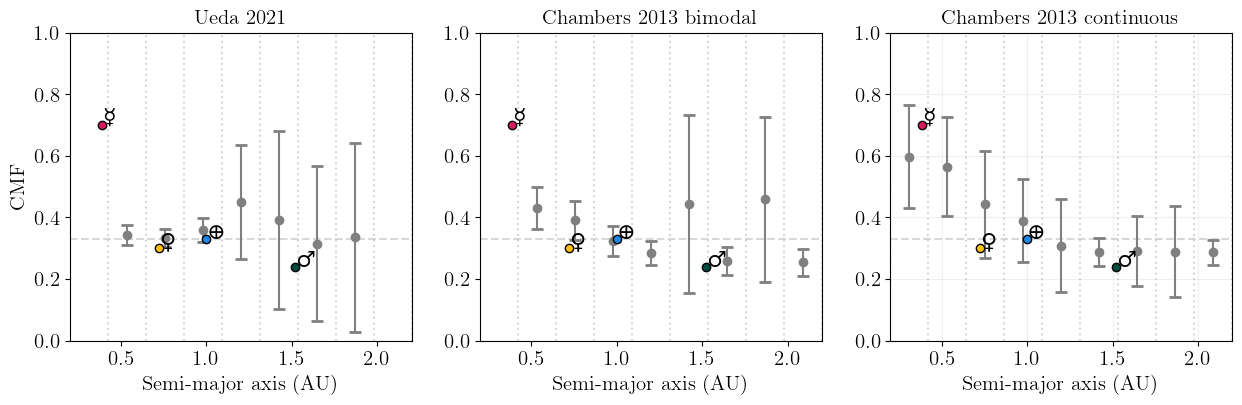

In [102]:
plt.figure(figsize=(15,4))
plt.subplot(1,3,1)
for edge in a_bin_edges:
    plt.axvline(edge, alpha = 0.3, linestyle=':', color = 'gray')
plt.errorbar(ueda_bin_centers[1:], ueda_cmf_means[1:], yerr=ueda_cmf_stds[1:], fmt = 'None', color = 'gray', capsize=4, capthick=2)
plt.scatter(ueda_bin_centers[1:], ueda_cmf_means[1:], color = 'gray', label = 'Ueda 2021')
plt.axhline(0.33, linestyle = '--', color = 'gray', alpha = 0.3)
plt.xlim(0.2, 2.2)
plt.ylim(0,1)
plt.xlabel('Semi-major axis (AU)')
plt.ylabel('CMF')
plt.title('Ueda 2021')
plot_solsys(5)

plt.subplot(1,3,2)
for edge in a_bin_edges:
    plt.axvline(edge, alpha = 0.3, linestyle=':', color = 'gray')
plt.errorbar(cham_b_bin_centers, cham_b_cmf_means, yerr=cham_b_cmf_stds, fmt = 'None', color = 'gray', capsize=4, capthick=2)
plt.scatter(cham_b_bin_centers, cham_b_cmf_means, color = 'gray', label = 'Chambers 2013 bimodal ')
plt.axhline(0.33, linestyle = '--', color = 'gray', alpha = 0.3)
plt.xlim(0.2, 2.2)
plt.ylim(0,1)
plt.xlabel('Semi-major axis (AU)')
plot_solsys(5)
plt.title('Chambers 2013 bimodal')

plt.subplot(1,3,3)
for edge in a_bin_edges:
    plt.axvline(edge, alpha = 0.3, linestyle=':', color = 'gray')
plt.errorbar(cham_c_bin_centers, cham_c_cmf_means, yerr=cham_c_cmf_stds, fmt = 'None', color = 'gray', capsize=4, capthick=2)
plt.scatter(cham_c_bin_centers, cham_c_cmf_means, color = 'gray', label = 'Chambers 2013 continuous')
plt.axhline(0.33, linestyle = '--', color = 'gray', alpha = 0.3)
plt.xlim(0.2, 2.2)
plt.ylim(0,1)
plot_solsys(5)
plt.title('Chambers 2013 continuous')


plt.xlabel('Semi-major axis (AU)')
plt.grid('True', alpha = 0.2)

plt.savefig('cmf_a_binned_simset_compare.pdf', dpi=300)
plt.show()

# Uniforms

In [99]:
ueda_unifs = pd.read_csv('../uniforms/ueda_v5_pldf_table.csv')
cham_bench_unifs = pd.read_csv('../uniforms/cham_bi_tajer_pldf_table.csv')
cham_cont_unifs = pd.read_csv('../uniforms/cham_cont_pldf_table.csv')

ueda_unif_cs, ueda_unif_means, ueda_unif_stds = bin_over_a(ueda_unifs, a_bin_edges)
cham_bench_unifs_cs, cham_bench_unifs_means, cham_bench_unifs_stds = bin_over_a(cham_bench_unifs, a_bin_edges)
cham_cont_unifs_cs, cham_cont_unifs_means, cham_cont_unifs_stds = bin_over_a(cham_cont_unifs, a_bin_edges)

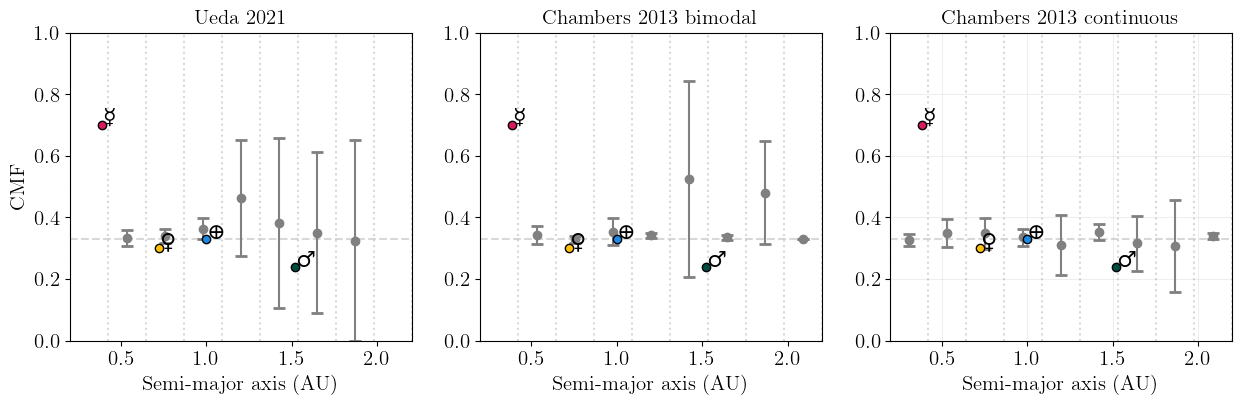

In [101]:
plt.figure(figsize=(15,4))
plt.subplot(1,3,1)
for edge in a_bin_edges:
    plt.axvline(edge, alpha = 0.3, linestyle=':', color = 'gray')
plt.errorbar(ueda_unif_cs[1:], ueda_unif_means[1:], yerr=ueda_unif_stds[1:], fmt = 'None', color = 'gray', capsize=4, capthick=2)
plt.scatter(ueda_unif_cs[1:], ueda_unif_means[1:], color = 'gray', label = 'Ueda 2021')
plt.axhline(0.33, linestyle = '--', color = 'gray', alpha = 0.3)
plt.xlim(0.2, 2.2)
plt.ylim(0,1)
plt.xlabel('Semi-major axis (AU)')
plt.ylabel('CMF')
plt.title('Ueda 2021')
plot_solsys(5)

plt.subplot(1,3,2)
for edge in a_bin_edges:
    plt.axvline(edge, alpha = 0.3, linestyle=':', color = 'gray')
plt.errorbar(cham_bench_unifs_cs, cham_bench_unifs_means, yerr=cham_bench_unifs_stds, fmt = 'None', color = 'gray', capsize=4, capthick=2)
plt.scatter(cham_bench_unifs_cs, cham_bench_unifs_means, color = 'gray', label = 'Chambers 2013 bimodal ')
plt.axhline(0.33, linestyle = '--', color = 'gray', alpha = 0.3)
plt.xlim(0.2, 2.2)
plt.ylim(0,1)
plt.xlabel('Semi-major axis (AU)')
plot_solsys(5)
plt.title('Chambers 2013 bimodal')

plt.subplot(1,3,3)
for edge in a_bin_edges:
    plt.axvline(edge, alpha = 0.3, linestyle=':', color = 'gray')
plt.errorbar(cham_cont_unifs_cs, cham_cont_unifs_means, yerr=cham_cont_unifs_stds, fmt = 'None', color = 'gray', capsize=4, capthick=2)
plt.scatter(cham_cont_unifs_cs, cham_cont_unifs_means, color = 'gray', label = 'Chambers 2013 continuous')
plt.axhline(0.33, linestyle = '--', color = 'gray', alpha = 0.3)
plt.xlim(0.2, 2.2)
plt.ylim(0,1)
plot_solsys(5)
plt.title('Chambers 2013 continuous')


plt.xlabel('Semi-major axis (AU)')
plt.grid('True', alpha = 0.2)

plt.savefig('cmf_a_binned_simset_compare_uniform.pdf', dpi=300)
plt.show()